In [1]:
from pathlib import Path #imports
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def plot_frequency_counts(counts, title, xlabel, ylabel = "Count"): #plot category frequencies in descending order
    series = pd.Series(counts).sort_values(ascending = False)

    plt.figure(figsize = (12, 5))
    sns.barplot(x = series.index, y = series.values)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation = 45, ha = "right")
    plt.tight_layout()
    plt.show()


def plot_numeric_distributions(data, columns, bins = 40): #plot histograms for selected numerical features
    for col in columns:
        if col not in data.columns:
            continue

        values = data[col].dropna()

        if values.empty:
            continue

        plt.figure(figsize = (8, 4))
        sns.histplot(values, bins = bins, kde = False)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

In [3]:
DATA_DIR = Path(r"C:\DATA 4380\Tabular Project") #path for folder holding Kaggle files; change if necessary

TRAIN_PATH = DATA_DIR / "train.csv" #paths for dataset files given by Kaggle
LABELS_PATH = DATA_DIR / "train_labels.csv"
TEST_PATH = DATA_DIR / "test.csv"
SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

for path in [ #verifying the files exist
    TRAIN_PATH,
    LABELS_PATH,
    TEST_PATH,
    SUBMISSION_PATH
]:
    if path.exists():
        print(f"{path.name:25} {path.stat().st_size / 1024**2:,.2f} MB")
    else:
        print(f"{path.name:25} NOT FOUND")

train.csv                 4,505.14 MB
train_labels.csv          9.51 MB
test.csv                  0.63 MB
sample_submission.csv     0.00 MB


In [4]:
train_sample = pd.read_csv( #taking a look at a small sample of training data
    TRAIN_PATH,
    nrows = 1_000,
    low_memory = False
)

print("Sample shape:", train_sample.shape)

print("\nColumn names:")
print(train_sample.columns.tolist())

print("\nData types:")
print(train_sample.dtypes)

print("\nFirst 5 rows:")
display(train_sample.head())

labels = pd.read_csv(LABELS_PATH, low_memory = False) #take a look at labels

print("Labels shape:", labels.shape)
print("\nLabel columns:")
print(labels.columns.tolist())

display(labels.head())

submission_sample = pd.read_csv(SUBMISSION_PATH) #take a look at submission format

print("\nSample submission shape:", submission_sample.shape)
display(submission_sample.head())

Sample shape: (1000, 20)

Column names:
['session_id', 'index', 'elapsed_time', 'event_name', 'name', 'level', 'page', 'room_coor_x', 'room_coor_y', 'screen_coor_x', 'screen_coor_y', 'hover_duration', 'text', 'fqid', 'room_fqid', 'text_fqid', 'fullscreen', 'hq', 'music', 'level_group']

Data types:
session_id          int64
index               int64
elapsed_time        int64
event_name         object
name               object
level               int64
page              float64
room_coor_x       float64
room_coor_y       float64
screen_coor_x     float64
screen_coor_y     float64
hover_duration    float64
text               object
fqid               object
room_fqid          object
text_fqid          object
fullscreen          int64
hq                  int64
music               int64
level_group        object
dtype: object

First 5 rows:


,session_id,index,elapsed_time,event_name,name,level,page,room_coor_x,room_coor_y,screen_coor_x,screen_coor_y,hover_duration,text,fqid,room_fqid,text_fqid,fullscreen,hq,music,level_group
0,20090312431273200,0,0,cutscene_click,basic,0,NaN,-413.991405,-159.314686,380.0,494.0,NaN,undefined,intro,tunic.historicalsociety.closet,tunic.historicalsociety.closet.intro,0,0,1,0-4
1,20090312431273200,1,1323,person_click,basic,0,NaN,-413.991405,-159.314686,380.0,494.0,NaN,"Whatcha doing over there, Jo?",gramps,tunic.historicalsociety.closet,tunic.historicalsociety.closet.gramps.intro_0_...,0,0,1,0-4
2,20090312431273200,2,831,person_click,basic,0,NaN,-413.991405,-159.314686,380.0,494.0,NaN,Just talking to Teddy.,gramps,tunic.historicalsociety.closet,tunic.historicalsociety.closet.gramps.intro_0_...,0,0,1,0-4
3,20090312431273200,3,1147,person_click,basic,0,NaN,-413.991405,-159.314686,380.0,494.0,NaN,I gotta run to my meeting!,gramps,tunic.historicalsociety.closet,tunic.historicalsociety.closet.gramps.intro_0_...,0,0,1,0-4
4,20090312431273200,4,1863,person_click,basic,0,NaN,-412.991405,-159.314686,381.0,494.0,NaN,"Can I come, Gramps?",gramps,tunic.historicalsociety.closet,tunic.historicalsociety.closet.gramps.intro_0_...,0,0,1,0-4


Labels shape: (424116, 2)

Label columns:
['session_id', 'correct']


,session_id,correct
0,20090312431273200_q1,1
1,20090312433251036_q1,0
2,20090312455206810_q1,1
3,20090313091715820_q1,0
4,20090313571836404_q1,1



Sample submission shape: (54, 3)


,session_id,correct,session_level
0,20090109393214576_q1,0,0
1,20090312143683264_q1,0,3
2,20090312331414616_q1,0,6
3,20090109393214576_q2,0,0
4,20090312143683264_q2,0,3


In [5]:
CHUNK_SIZE = 250_000 #loading the large event file in chunks to avoid memory issues

total_rows = 0
missing_counts = Counter()
session_ids = set()
category_counts = {}
duplicate_rows_within_chunks = 0
first_dtypes = None

for chunk_number, chunk in enumerate(
    pd.read_csv(
        TRAIN_PATH,
        chunksize = CHUNK_SIZE,
        low_memory = False
    ),
    start = 1
):
    total_rows += len(chunk)

    if first_dtypes is None: #record the data types from the first chunk
        first_dtypes = chunk.dtypes.astype(str).to_dict()

    for col, count in chunk.isna().sum().items(): #missing value counts for each column in the chunk
        missing_counts[col] += int(count)

    if "session_id" in chunk.columns: #count unique session IDs in the chunk and add to the set
        session_ids.update(chunk["session_id"].dropna().unique())

    for col in ["event_name", "name", "level_group"]: #track the counts of categorical values for these columns
        if col in chunk.columns:
            if col not in category_counts:
                category_counts[col] = Counter()

            category_counts[col].update(
                chunk[col].value_counts(dropna=False).to_dict()
            )

    duplicate_rows_within_chunks += int( #detect duplicates within each chunk
        chunk.duplicated().sum()
    )

    if chunk_number % 10 == 0: #progress indicator
        print(
            f"Processed {total_rows:,} rows "
            f"across {chunk_number} chunks"
        )

Processed 2,500,000 rows across 10 chunks
Processed 5,000,000 rows across 20 chunks
Processed 7,500,000 rows across 30 chunks
Processed 10,000,000 rows across 40 chunks
Processed 12,500,000 rows across 50 chunks
Processed 15,000,000 rows across 60 chunks
Processed 17,500,000 rows across 70 chunks
Processed 20,000,000 rows across 80 chunks
Processed 22,500,000 rows across 90 chunks
Processed 25,000,000 rows across 100 chunks


In [6]:
print("\n--- Full Event Dataset Summary ---") #event dataset summary
print(f"Total rows: {total_rows:,}")
print(f"Number of columns: {len(first_dtypes)}")
print(f"Unique session IDs: {len(session_ids):,}")

print("\nData types (first chunk):")
print(pd.Series(first_dtypes))

print("\nMissing values:")
print(
    pd.Series(missing_counts)
      .sort_values(ascending=False)
)

print("\nDuplicate rows found within chunks:")
print(f"{duplicate_rows_within_chunks:,}")

for col, counts in category_counts.items():
    print(f"\nTop values in {col}:")
    print(counts.most_common(15))

print("\nTarget data types:") #target distribution
print(labels.dtypes)

print("\nTarget missing values:")
print(labels.isna().sum())

print("\nTarget class counts:")
print(labels["correct"].value_counts(dropna = False).sort_index())

print("\nTarget class proportions:")
print(
    labels["correct"]
    .value_counts(normalize = True, dropna = False)
    .sort_index()
    .round(4)
)


--- Full Event Dataset Summary ---
Total rows: 26,296,946
Number of columns: 20
Unique session IDs: 23,562

Data types (first chunk):
session_id          int64
index               int64
elapsed_time        int64
event_name         object
name               object
level               int64
page              float64
room_coor_x       float64
room_coor_y       float64
screen_coor_x     float64
screen_coor_y     float64
hover_duration    float64
text               object
fqid               object
room_fqid          object
text_fqid          object
fullscreen          int64
hq                  int64
music               int64
level_group        object
dtype: object

Missing values:
page              25732402
hover_duration    24294702
text              16679807
text_fqid         16679702
fqid               8274415
screen_coor_x      2073272
room_coor_y        2073272
room_coor_x        2073272
screen_coor_y      2073272
elapsed_time             0
index                    0
session_id       

In [7]:
labels["question"] = labels["session_id"].str.extract( #inspect how target labels are organized
       r"_(q\d+)$"
   )

labels["base_session_id"] = labels["session_id"].str.replace(
    r"_q\d+$", "", regex=True
)

print("Number of labeled question rows:", len(labels))
print(
    "Unique session-question identifiers:",
    labels["session_id"].nunique()
)
print(
    "Unique base sessions:",
    labels["base_session_id"].nunique()
)

print("\nQuestion counts:")
print(labels["question"].value_counts().sort_index())

print("\nCorrectness by question:")
question_summary = labels.groupby("question")["correct"].agg(
    ["count", "mean"]
)

question_summary = question_summary.rename(
    columns={"count": "observations", "mean": "accuracy"}
)

print(question_summary.round(4))

labels_per_session = labels.groupby(
    "base_session_id"
).size()

print("\nLabels per session:")
print(labels_per_session.value_counts().sort_index())

Number of labeled question rows: 424116
Unique session-question identifiers: 424116
Unique base sessions: 23562

Question counts:
question
q1     23562
q10    23562
q11    23562
q12    23562
q13    23562
q14    23562
q15    23562
q16    23562
q17    23562
q18    23562
q2     23562
q3     23562
q4     23562
q5     23562
q6     23562
q7     23562
q8     23562
q9     23562
Name: count, dtype: int64

Correctness by question:
          observations  accuracy
question                        
q1               23562    0.7275
q10              23562    0.5054
q11              23562    0.6436
q12              23562    0.8630
q13              23562    0.2751
q14              23562    0.7077
q15              23562    0.4810
q16              23562    0.7349
q17              23562    0.6878
q18              23562    0.9506
q2               23562    0.9788
q3               23562    0.9340
q4               23562    0.7982
q5               23562    0.5483
q6               23562    0.7760
q7            

In [8]:
session_stats = {} #scan the event log in chunks to summarize session-level event counts

for chunk in pd.read_csv(
    TRAIN_PATH,
    chunksize = 250_000,
    low_memory = False
):
    grouped = chunk.groupby(
        ["session_id", "level_group"],
        observed = True
    ).size()

    for (session_id, level_group), event_count in grouped.items():
        session_id = int(session_id)

        if session_id not in session_stats:
            session_stats[session_id] = {
                "session_id": session_id,
                "total_events": 0,
                "events_0_4": 0,
                "events_5_12": 0,
                "events_13_22": 0,
            }

        session_stats[session_id]["total_events"] += int(
            event_count
        )

        column_map = {
            "0-4": "events_0_4",
            "5-12": "events_5_12",
            "13-22": "events_13_22",
        }

        if level_group in column_map:
            column = column_map[level_group]
            session_stats[session_id][column] += int(
                event_count
            )

session_summary = pd.DataFrame(
    list(session_stats.values())
)

In [9]:
print("\nSession summary shape:", session_summary.shape)
display(session_summary.head())

print("\nEvents per session:")
display(
    session_summary["total_events"].describe().round(2)
)

print("\nEvent counts by level group:")
display(
    session_summary[
        ["events_0_4", "events_5_12", "events_13_22"]
    ].describe().round(2)
)

labeled_session_ids = set( #combine sessions in event log with labeled sessions
    labels["base_session_id"].astype("int64")
)

event_session_ids = set(
    session_summary["session_id"].astype("int64")
)

print("\nSession ID comparison")
print("Sessions in event log:", len(event_session_ids))
print("Sessions in labels:", len(labeled_session_ids))
print(
    "Labeled sessions found in event log:",
    len(labeled_session_ids & event_session_ids)
)
print(
    "Labeled sessions absent from event log:",
    len(labeled_session_ids - event_session_ids)
)
print(
    "Event sessions without labels:",
    len(event_session_ids - labeled_session_ids)
)


Session summary shape: (23562, 5)


,session_id,total_events,events_0_4,events_5_12,events_13_22
0,20090312431273200,881,165,296,420
1,20090312433251036,1831,139,395,1297
2,20090312455206810,758,149,245,364
3,20090313091715820,993,176,326,491
4,20090313571836404,746,112,242,392



Events per session:


count    23562.00
mean      1116.07
std        352.85
min        591.00
25%        901.00
50%       1033.00
75%       1231.00
max      19032.00
Name: total_events, dtype: float64


Event counts by level group:


,events_0_4,events_5_12,events_13_22
count,23562.00,23562.00,23562.00
mean,168.96,375.36,571.76
std,52.48,155.46,208.87
min,85.00,206.00,291.00
25%,137.00,294.00,443.00
50%,158.00,340.00,515.00
75%,187.00,416.00,635.00
max,2628.00,14255.00,4702.00



Session ID comparison
Sessions in event log: 23562
Sessions in labels: 23562
Labeled sessions found in event log: 23562
Labeled sessions absent from event log: 0
Event sessions without labels: 0


In [10]:
event_counts = Counter() #scan the event CSV in chunks to summarize event-level statistics
level_counts = Counter()
event_level_counts = Counter()
missing_by_event = Counter()
total_by_event = Counter()
samples = []

numeric_columns = [
    "elapsed_time",
    "level",
    "page",
    "room_coor_x",
    "room_coor_y",
    "screen_coor_x",
    "screen_coor_y",
    "hover_duration",
]

categorical_columns = [
    "event_name",
    "name",
    "fqid",
    "room_fqid",
    "text_fqid",
    "text",
]

for chunk in pd.read_csv(
    TRAIN_PATH,
    chunksize = 250_000,
    low_memory = False
):
    event_counts.update(
        chunk["event_name"].value_counts().to_dict()
    )

    level_counts.update(
        chunk["level_group"].value_counts().to_dict()
    )

    event_level_counts.update(
        chunk.groupby(
            ["event_name", "level_group"],
            observed = True
        ).size().to_dict()
    )

    for event_name, group in chunk.groupby( #missingness counts, grouped by event type
        "event_name", observed = True
    ):
        total_by_event[event_name] += len(group)

        for col in chunk.columns:
            missing_by_event[(event_name, col)] += int(
                group[col].isna().sum()
            )

    available_numeric = [ #sample numerical values for exploratory plots
        col for col in numeric_columns
        if col in chunk.columns
    ]

    if len(chunk) > 0: #sample rows from each chunk with a fixed seed
        samples.append(
            chunk[available_numeric].sample(
                n = min(1_000, len(chunk)),
                random_state = 42
            )
        )

numeric_sample = pd.concat(
    samples, ignore_index=True
)

if len(numeric_sample) > 100_000: #limit the final sample size if the scan produced more rows
    numeric_sample = numeric_sample.sample(
        n = 100_000,
        random_state = 42
    )

In [11]:
print("Numerical sample shape:", numeric_sample.shape)

print("\nEvent frequencies:")
display(pd.Series(event_counts).sort_values(ascending=False))

print("\nLevel-group frequencies:")
display(pd.Series(level_counts).sort_index())

print("\nEvent counts by event type and level group:")
event_level_table = pd.DataFrame(
    event_level_counts.items(),
    columns=["event_name_level_group", "count"]
)
display(event_level_table.head(20))

Numerical sample shape: (100000, 8)

Event frequencies:


navigate_click        11326433
person_click           6052853
cutscene_click         2703035
object_click           2198211
object_hover           1057085
map_hover               945159
notification_click      649001
notebook_click          564544
map_click               517242
observation_click       212355
checkpoint               71028
dtype: int64


Level-group frequencies:


0-4       3981005
13-22    13471703
5-12      8844238
dtype: int64


Event counts by event type and level group:


,event_name_level_group,count
0,"(checkpoint, 0-4)",23713
1,"(checkpoint, 13-22)",23633
2,"(checkpoint, 5-12)",23682
3,"(cutscene_click, 0-4)",787584
4,"(cutscene_click, 13-22)",1623072
5,"(cutscene_click, 5-12)",292379
6,"(map_click, 0-4)",54068
7,"(map_click, 13-22)",257860
8,"(map_click, 5-12)",205314
9,"(map_hover, 0-4)",45130


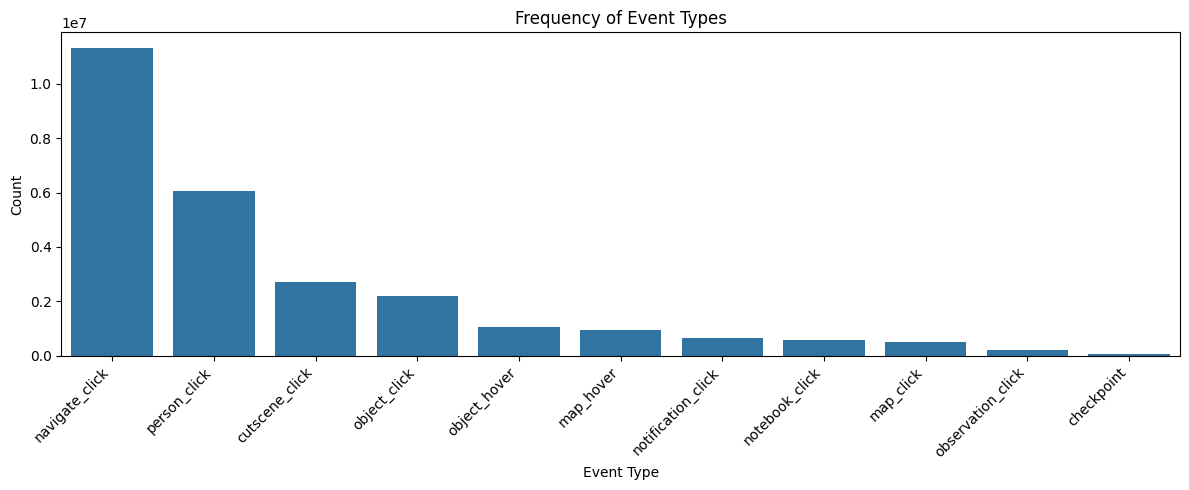

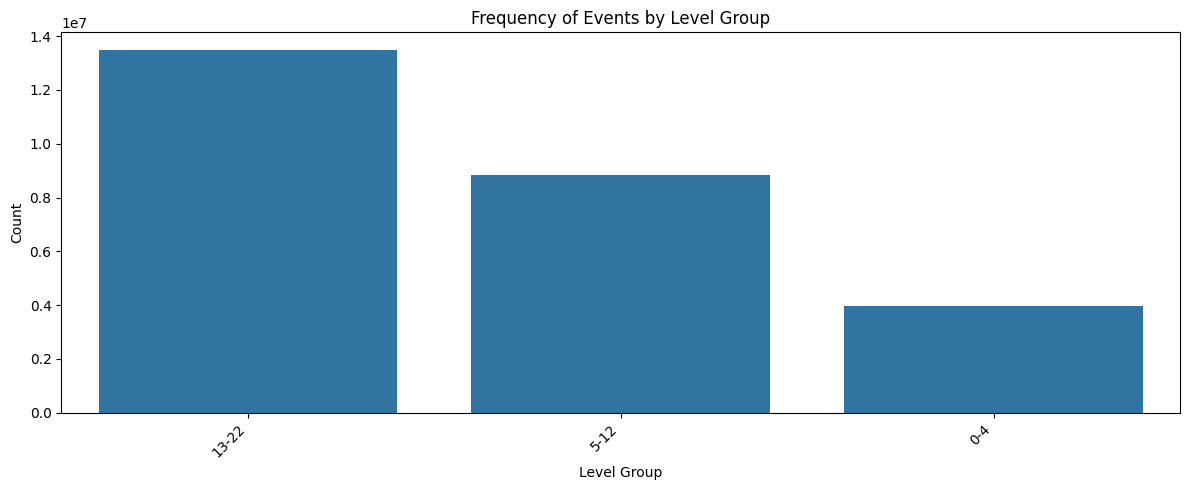

In [12]:
plot_frequency_counts(
    event_counts,
    title="Frequency of Event Types",
    xlabel="Event Type"
)

plot_frequency_counts(
    level_counts,
    title="Frequency of Events by Level Group",
    xlabel="Level Group"
)

In [13]:
missing_rows = []

for (event_name, column), missing_count in missing_by_event.items():
    total = total_by_event[event_name]

    missing_rows.append({
        "event_name": event_name,
        "feature": column,
        "missing_count": missing_count,
        "total_events": total,
        "missing_percent": 100 * missing_count / total
    })

missing_by_event_df = pd.DataFrame(missing_rows)

missing_summary = ( #focus on features with missing values, sorted by feature and missing percentage
    missing_by_event_df[
        missing_by_event_df["missing_count"] > 0
    ]
    .sort_values(
        ["feature", "missing_percent"],
        ascending = [True, False]
    )
)

display(missing_summary.head(40))

,event_name,feature,missing_count,total_events,missing_percent
113,notebook_click,fqid,564544,564544,100.000000
133,notification_click,fqid,649001,649001,100.000000
93,navigate_click,fqid,6986160,11326433,61.680142
53,map_click,fqid,74710,517242,14.443916
11,checkpoint,hover_duration,71028,71028,100.000000
31,cutscene_click,hover_duration,2703035,2703035,100.000000
51,map_click,hover_duration,517242,517242,100.000000
91,navigate_click,hover_duration,11326433,11326433,100.000000
111,notebook_click,hover_duration,564544,564544,100.000000
131,notification_click,hover_duration,649001,649001,100.000000


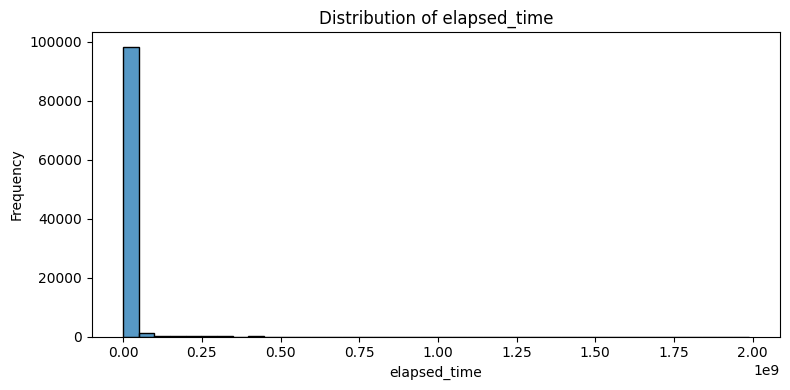

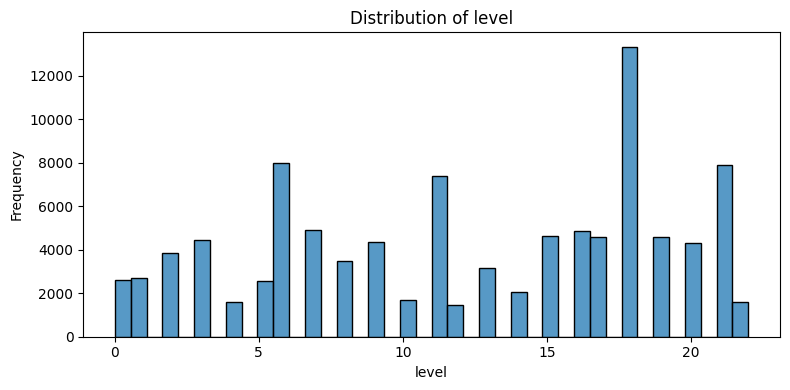

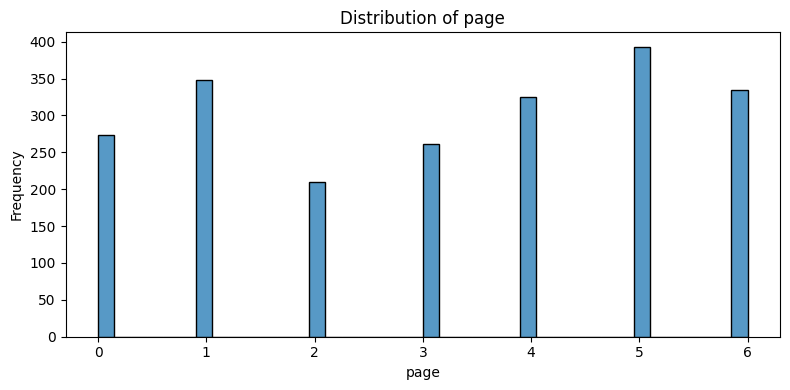

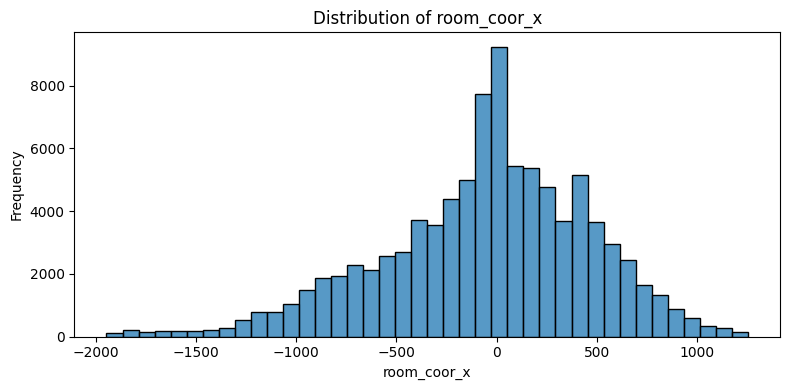

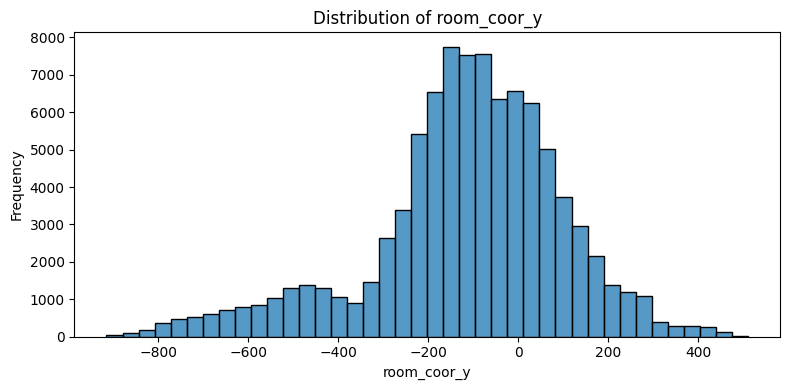

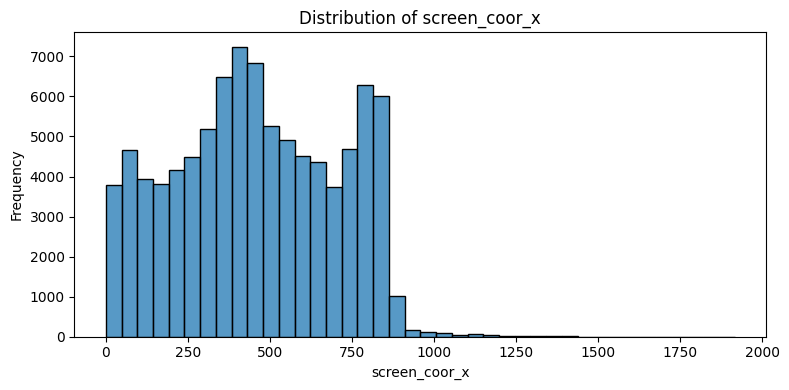

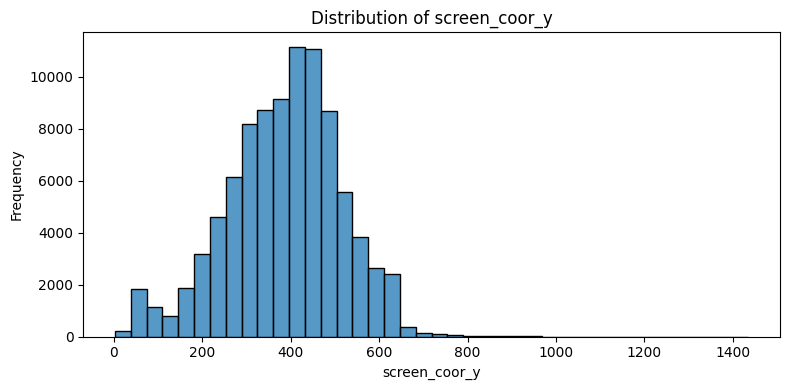

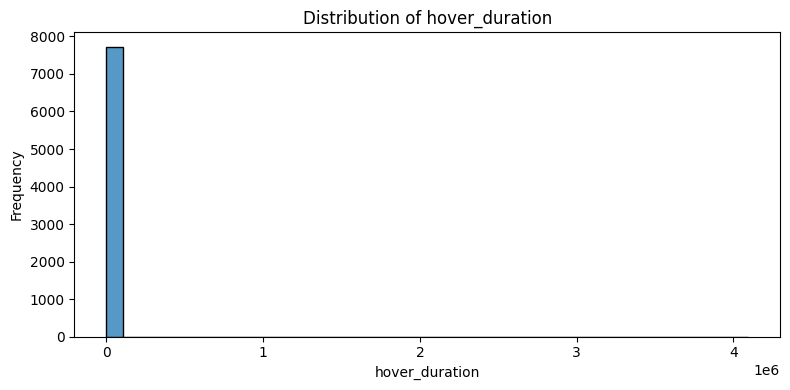

In [14]:
plot_numeric_distributions(
    numeric_sample,
    columns = [
        "elapsed_time",
        "level",
        "page",
        "room_coor_x",
        "room_coor_y",
        "screen_coor_x",
        "screen_coor_y",
        "hover_duration",
    ]
)

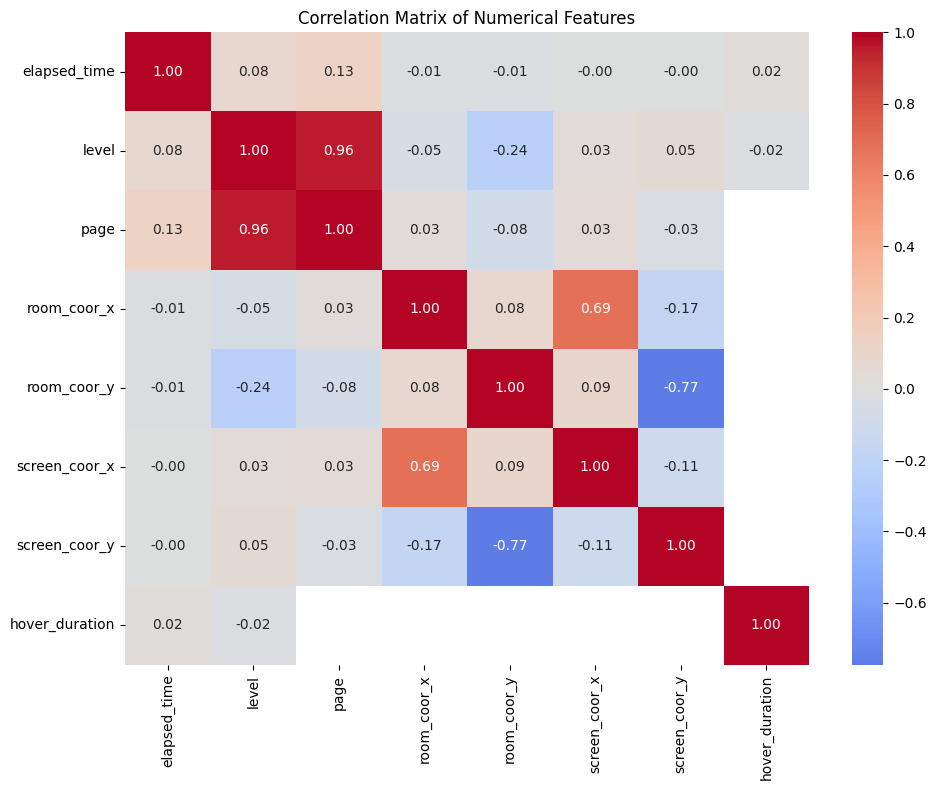

In [15]:
correlation_columns = [
    "elapsed_time",
    "level",
    "page",
    "room_coor_x",
    "room_coor_y",
    "screen_coor_x",
    "screen_coor_y",
    "hover_duration",
]

correlation_matrix = numeric_sample[
    correlation_columns
].corr()

plt.figure(figsize = (10, 8))
sns.heatmap(
    correlation_matrix,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm",
    center = 0
)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [16]:
print("Numerical feature summaries:") #descriptive statistics for numerical features
display(
    numeric_sample.describe()
    .T
    .round(2)
)

print("\nNumerical feature skewness:") #skewness for numerical features, sorted in descending order
display(
    numeric_sample.skew()
    .sort_values(ascending=False)
    .round(2)
)

Numerical feature summaries:


,count,mean,std,min,25%,50%,75%,max
elapsed_time,100000.0,4006242.36,30714506.38,0.00,438477.25,1009290.00,1745858.00,1.987396e+09
level,100000.0,12.16,6.49,0.00,6.00,13.00,18.00,2.200000e+01
page,2145.0,3.18,2.04,0.00,1.00,3.00,5.00,6.000000e+00
room_coor_x,92002.0,-56.52,519.88,-1946.06,-355.12,-11.52,295.22,1.253270e+03
room_coor_y,92002.0,-115.83,218.58,-915.50,-212.04,-97.00,23.76,5.106800e+02
screen_coor_x,92002.0,458.19,248.36,0.00,267.00,446.00,663.00,1.917000e+03
screen_coor_y,92002.0,385.53,129.67,2.00,303.00,397.00,471.00,1.435000e+03
hover_duration,7726.0,1925.76,46665.84,0.00,93.50,417.00,1258.75,4.092767e+06



Numerical feature skewness:


hover_duration    87.23
elapsed_time      28.88
screen_coor_x      0.05
page              -0.15
screen_coor_y     -0.22
level             -0.24
room_coor_x       -0.52
room_coor_y       -0.71
dtype: float64

In [17]:
for column in ["elapsed_time", "hover_duration"]: #inspect extreme values in the existing numerical sample
    print(f"\nLargest sampled values for {column}:")
    display(
        numeric_sample[column]
        .dropna()
        .nlargest(10)
        .to_frame()
    )


Largest sampled values for elapsed_time:


,elapsed_time
50199,1987396334
50291,1986984600
50501,1986851387
84604,1749252383
84762,1747339530
84884,1746680121
80676,1195770934
80431,1195684526
80272,1195601526
104127,1189229083



Largest sampled values for hover_duration:


,hover_duration
79351,4092767.0
73277,130255.0
518,90809.0
3179,87607.0
12659,50769.0
34351,40126.0
32817,39012.0
100027,38436.0
41541,35113.0
105878,34135.0
